<a href="https://colab.research.google.com/github/biswal-prem-5677/10xCoders-Platform/blob/main/ai/03_deep_learning/architectures/cnn/experiment_cnn_feature_extraction_operations.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



### CNN Feature Extraction Operations

1. **Input image** — image is loaded and converted into a numerical tensor.
2. **Resizing** — converts the image to a fixed size of 128×128 pixels.
3. **Normalization** — scales pixel values from 0–255 to 0–1.
4. **Convolution** — filters scan local regions and generate feature maps.
5. **ReLU activation** — introduces non-linearity and keeps positive activations.
6. **Batch Normalization** — normalizes intermediate activations.
7. **Max Pooling** — reduces spatial dimensions while retaining strong responses.
8. **Average Pooling** — reduces dimensions using local averages.
9. **Repeated convolution blocks** — progressively learn higher-level features.
10. **Final feature maps** — represent learned spatial features before flattening.
11. **Flatten** — converts the feature maps into a vector for a dense classification head.

### Key Concept

Early CNN layers generally respond to low-level patterns such as edges and textures, while deeper layers combine these patterns into increasingly complex representations. Pooling progressively reduces spatial resolution while preserving important activation information.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing import image
from google.colab import files

print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.20.0


Saving lion 4.jpg to lion 4.jpg
Original image shape: (2000, 2000, 3)


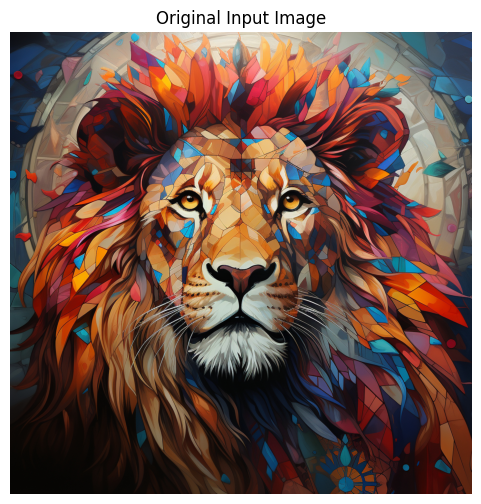

In [2]:
uploaded = files.upload()
img_path = next(iter(uploaded))

img = image.load_img(img_path)
img_array = image.img_to_array(img)

print("Original image shape:", img_array.shape)

plt.figure(figsize=(6, 6))
plt.imshow(img)
plt.axis("off")
plt.title("Original Input Image")
plt.show()


Resized image shape: (128, 128, 3)
Input tensor shape: (1, 128, 128, 3)
Pixel range: 0.0 to 1.0


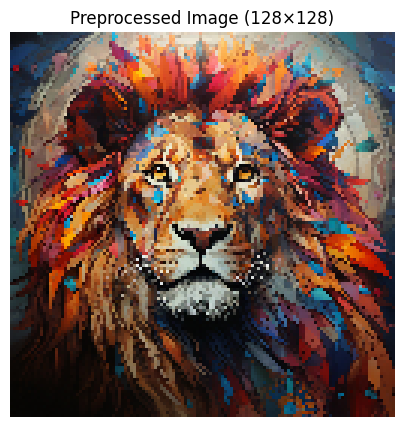

In [3]:
IMG_SIZE = (128, 128)

img_resized = tf.image.resize(img_array, IMG_SIZE)
img_normalized = img_resized / 255.0
input_tensor = tf.expand_dims(img_normalized, axis=0)

print("Resized image shape:", img_resized.shape)
print("Input tensor shape:", input_tensor.shape)
print("Pixel range:", float(tf.reduce_min(input_tensor)), "to", float(tf.reduce_max(input_tensor)))

plt.figure(figsize=(5, 5))
plt.imshow(img_normalized)
plt.axis("off")
plt.title("Preprocessed Image (128×128)")
plt.show()


In [4]:
conv_demo = layers.Conv2D(
    filters=8,
    kernel_size=(3, 3),
    padding="same",
    use_bias=True
)

conv_output = conv_demo(input_tensor)

print("Input shape:", input_tensor.shape)
print("After Conv2D:", conv_output.shape)


Input shape: (1, 128, 128, 3)
After Conv2D: (1, 128, 128, 8)


In [5]:
relu_output = tf.nn.relu(conv_output)

print("After ReLU:", relu_output.shape)
print("Minimum before ReLU:", float(tf.reduce_min(conv_output)))
print("Minimum after ReLU:", float(tf.reduce_min(relu_output)))


After ReLU: (1, 128, 128, 8)
Minimum before ReLU: -0.8521440029144287
Minimum after ReLU: 0.0


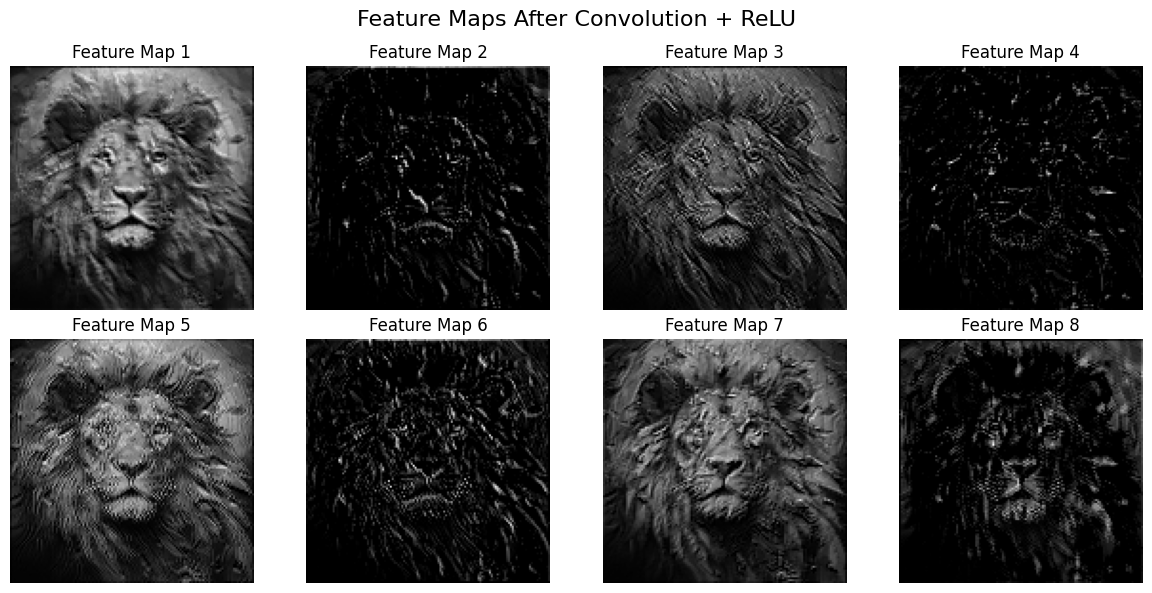

In [6]:
def show_feature_maps(feature_tensor, title, max_maps=8):
    feature_maps = feature_tensor[0].numpy()
    n = min(feature_maps.shape[-1], max_maps)
    cols = 4
    rows = int(np.ceil(n / cols))

    plt.figure(figsize=(12, 3 * rows))
    for i in range(n):
        plt.subplot(rows, cols, i + 1)
        plt.imshow(feature_maps[:, :, i], cmap="gray")
        plt.title(f"Feature Map {i + 1}")
        plt.axis("off")

    plt.suptitle(title, fontsize=16)
    plt.tight_layout()
    plt.show()

show_feature_maps(relu_output, "Feature Maps After Convolution + ReLU")


Before Max Pooling: (1, 128, 128, 8)
After Max Pooling: (1, 64, 64, 8)


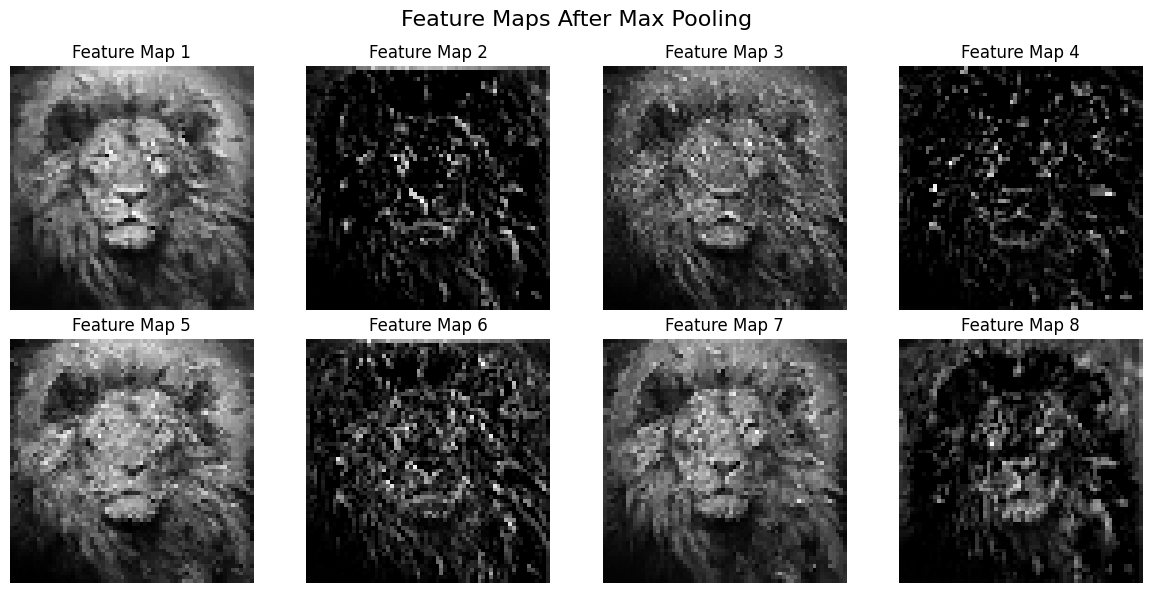

In [7]:
max_pool = layers.MaxPooling2D(pool_size=(2, 2), strides=2)
max_pool_output = max_pool(relu_output)

print("Before Max Pooling:", relu_output.shape)
print("After Max Pooling:", max_pool_output.shape)

show_feature_maps(max_pool_output, "Feature Maps After Max Pooling")


Before Average Pooling: (1, 128, 128, 8)
After Average Pooling: (1, 64, 64, 8)


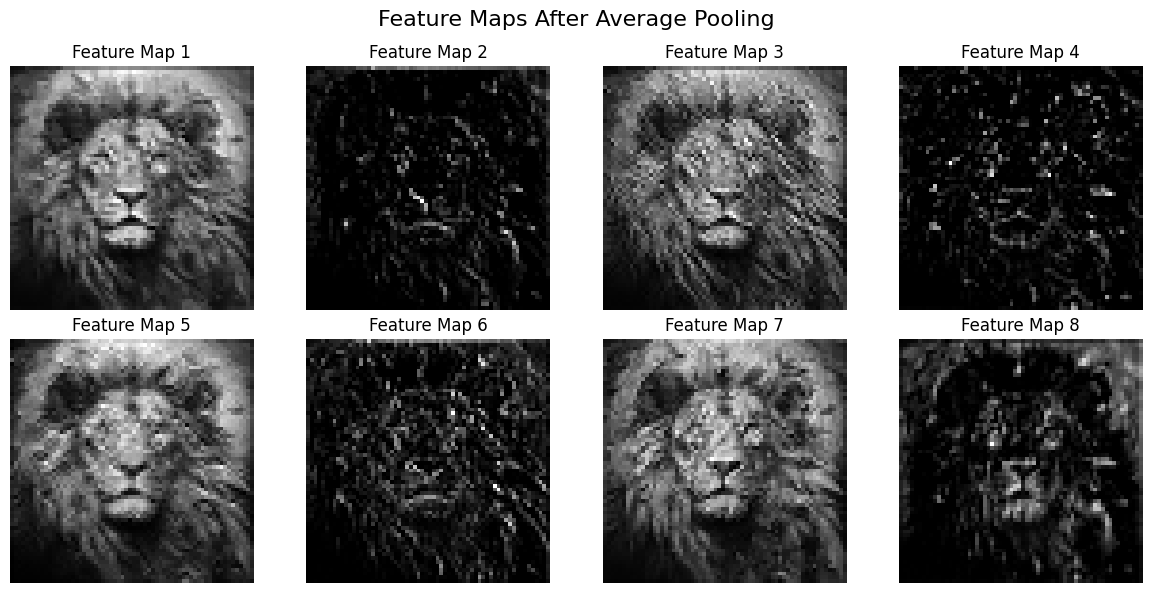

In [8]:
avg_pool = layers.AveragePooling2D(pool_size=(2, 2), strides=2)
avg_pool_output = avg_pool(relu_output)

print("Before Average Pooling:", relu_output.shape)
print("After Average Pooling:", avg_pool_output.shape)

show_feature_maps(avg_pool_output, "Feature Maps After Average Pooling")


In [9]:
batch_norm = layers.BatchNormalization()
bn_output = batch_norm(conv_output, training=True)

print("Before Batch Normalization:", conv_output.shape)
print("After Batch Normalization:", bn_output.shape)


Before Batch Normalization: (1, 128, 128, 8)
After Batch Normalization: (1, 128, 128, 8)


In [10]:
feature_extractor = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    layers.Conv2D(32, (3, 3), padding="same"),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), padding="same"),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), padding="same"),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.MaxPooling2D((2, 2))
], name="CNN_Feature_Extractor")

feature_extractor.summary()


Model: "CNN_Feature_Extractor"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 94,144 (367.75 KB)

 Trainable params: 93,696 (366.00 KB)

 Non-trainable params: 448 (1.75 KB)

In [11]:
final_feature_maps = feature_extractor(input_tensor, training=False)

print("Input:", input_tensor.shape)
print("Final feature-map tensor:", final_feature_maps.shape)
print("Number of extracted channels/features:", final_feature_maps.shape[-1])


Input: (1, 128, 128, 3)
Final feature-map tensor: (1, 16, 16, 128)
Number of extracted channels/features: 128


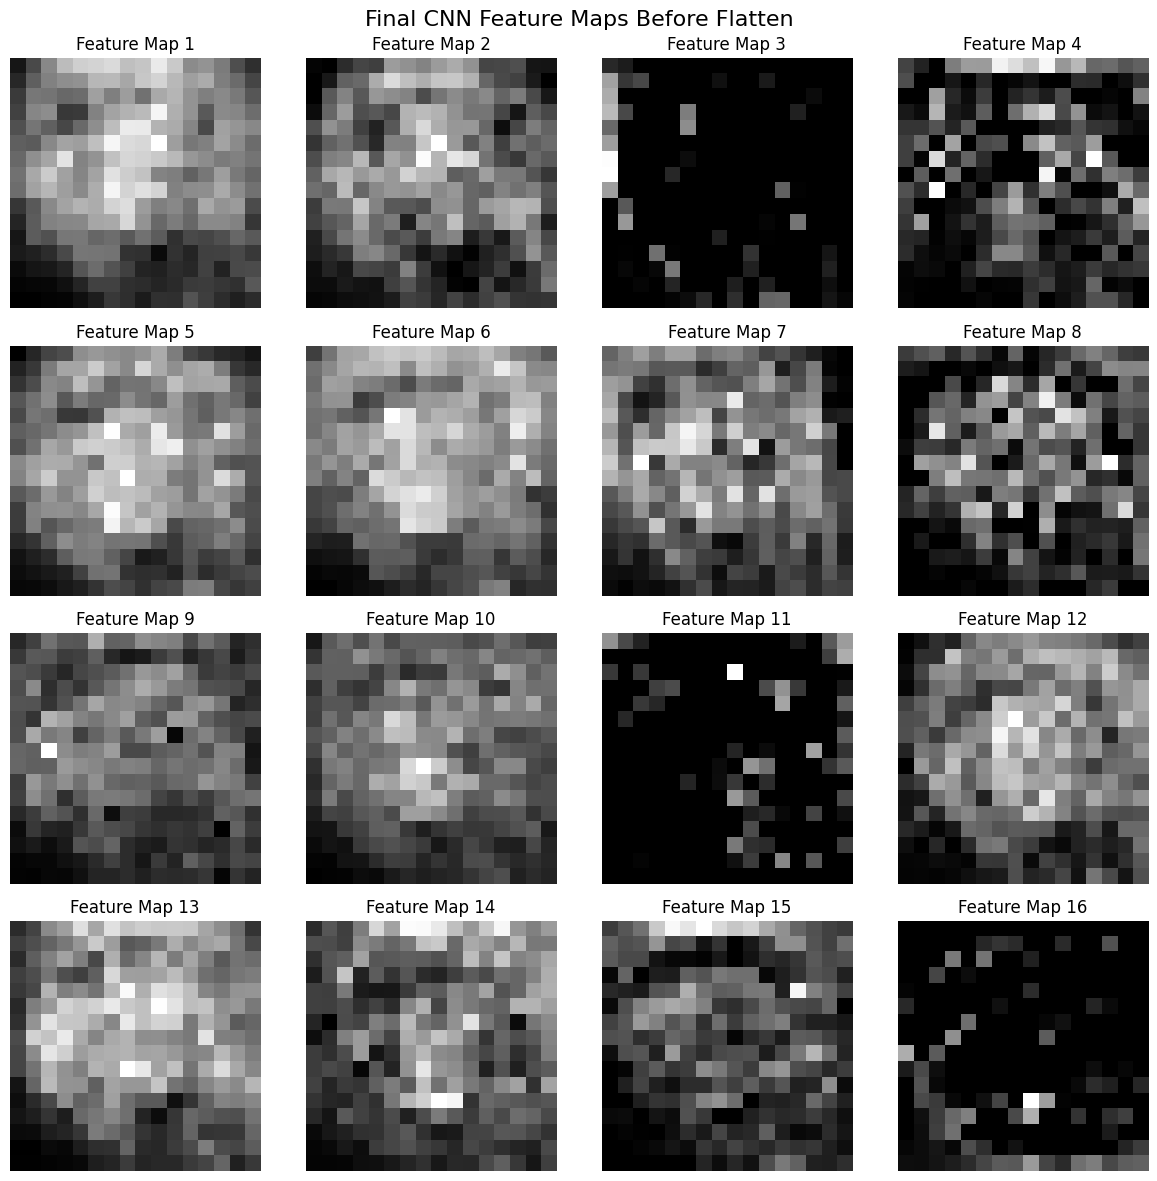

In [12]:
show_feature_maps(
    final_feature_maps,
    "Final CNN Feature Maps Before Flatten",
    max_maps=16
)


In [13]:
x = input_tensor
print("Input:", x.shape)

for layer in feature_extractor.layers:
    if isinstance(layer, layers.BatchNormalization):
        x = layer(x, training=False)
    else:
        x = layer(x)
    print(f"{layer.name:25s} -> {x.shape}")


Input: (1, 128, 128, 3)
conv2d_1                  -> (1, 128, 128, 32)
batch_normalization_1     -> (1, 128, 128, 32)
re_lu                     -> (1, 128, 128, 32)
max_pooling2d_1           -> (1, 64, 64, 32)
conv2d_2                  -> (1, 64, 64, 64)
batch_normalization_2     -> (1, 64, 64, 64)
re_lu_1                   -> (1, 64, 64, 64)
max_pooling2d_2           -> (1, 32, 32, 64)
conv2d_3                  -> (1, 32, 32, 128)
batch_normalization_3     -> (1, 32, 32, 128)
re_lu_2                   -> (1, 32, 32, 128)
max_pooling2d_3           -> (1, 16, 16, 128)


In [14]:
flatten = layers.Flatten()
flattened_features = flatten(final_feature_maps)

print("Before Flatten:", final_feature_maps.shape)
print("After Flatten:", flattened_features.shape)
print("Total flattened features:", flattened_features.shape[-1])


Before Flatten: (1, 16, 16, 128)
After Flatten: (1, 32768)
Total flattened features: 32768


In [15]:
classification_head = models.Sequential([
    layers.Input(shape=(flattened_features.shape[-1],)),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(10, activation="softmax")
])

classification_head.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,195,722 (16.01 MB)

 Trainable params: 4,195,722 (16.01 MB)

 Non-trainable params: 0 (0.00 B)